Lecture 11 will cover how to write actual applictions, the main function, input arguments, and beginning graphical user interfaces with layouts.

Reference
 * PyQt and documentation

# The entry point

Before we venture into graphical user interfaces, we should first cover the `main` function.
`main` is the common name for the entry point of executed programs. 

In C/C++ the main method reads as
```cpp
int main(int argc, const char* argv[]) {
    ...
}
```
in Java it's
```java
public static void main(String[] args) {
    ...
}
```


http://en.wikipedia.org/wiki/Entry_point

## Input arguments

What these main functions have in common, are the "arg" argument.
This is the list of strings that are given as the program is executed by the the user. 
A typical example of running a console program would look like:
```
$ python myprogram.py -f somefilename.txt -o output.txt -l 4
```
The program then gets the list of strings `['-f', 'somefilename.txt', '-o', 'output.txt', '-l', '4']`, and is free to decide what to do with them.

Since thousands of command line utilities use advanced input arguments, there exists libraries (often a standardized library for every language) that makes complex input arguments easier to handle.

When you select to *open a file with ...* in graphical shells (i.e. Windows, OSX, Gnome, etc.), what actually happens is that
```
$ program path/to/filename
```
that is, the full path to the filename as sent to the main program as the only argument.

## Pythons entry point

When you run a python script the special variable `__name__` is set to `"__main__"`.

A common setup in Python looks like
```python
def main():
    # my code here

if __name__ == "__main__":
    main()
```
which runs the `main()` function when the script is executed, but not with the file it included as a library.

## Pythons input arguments

To access the input arguments, one has to import the `sys` module

```python
import sys

def main():
    # First we check for correct user input
    if len(sys.argv) < 2:
        print("Filename not supplied, giving up.")
        return
    
    # argv[0] is the name of the script itself
    # and here we assume the user have input a 
    # filename as the second argument
    filename = sys.argv[1]
    do_more_stuff(filename)

if __name__ == "__main__":
    main()
```

### Complex input argument parsing

The OptionParser package allows for the type of advanced input arguments found in many command line tools (e.g. compilers)

```python
from optparse import OptionParser

parser = OptionParser()
parser.add_option("-f", "--file", dest="filename",
                  help="write report to FILE", metavar="FILE")
parser.add_option("-q", "--quiet",
                  action="store_false", dest="verbose", default=True,
                  help="don't print status messages to stdout")

(options, args) = parser.parse_args()
```

# Graphical User Interfaces (GUI)

For developing GUI, several widget-toolkits exist, for example some cross-platform widgets toolkits are

 * Qt
 * GTK
 * wxWidgets
 * FLTK
 
A `widget` is a *graphical control element*, such as a button, windows, textboxes, layout schemes, color selection input.
 
Designing the layouts in widget based software is often done with graphical tools, for example QtCreator:
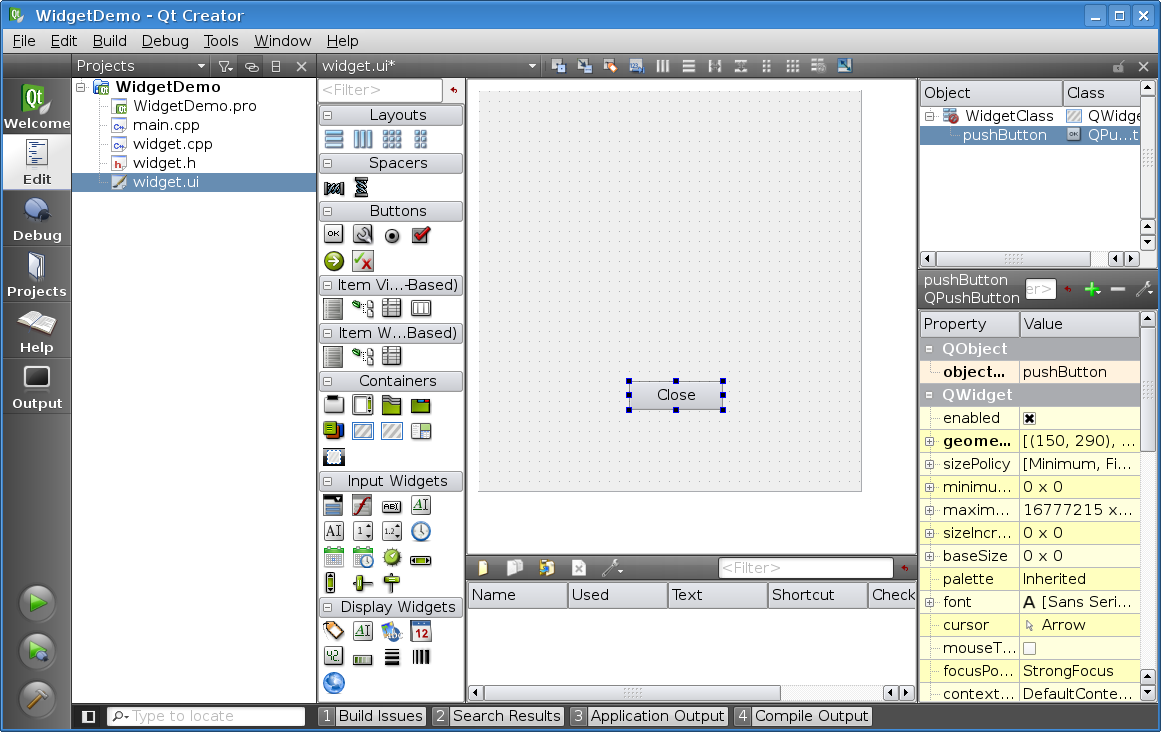

### Language bindings

To use these toolkits in you either use the language they are written in (Qt being written in C++), or you use a language binding to what you prefer/need to use. The language binding supplies the glue code to the toolkit.

There are primarily 2 options for Python and Qt, *PyQt* and *PySide*, which are very similar.

### Non widget based toolkits

If you need to make something graphical, but not with widgets (such as a game), then there are libraries like SDL (Simple Directmedia Layer) which enables convenient use of drawing areas (cross platform) where you are free to draw whatever you need yourself.

## Application = GUI + library

To keep development manageable, it is important to seperate the *engine* from the *graphics*. In most applications, this means to create a library that does the business logic, and a GUI-code that uses the library and simply presents the information to the user.

Many applications have multiple interfaces, supporting both a GTK and Qt GUI, and even command line and console interfaces, all using the same library. 

The next lecture will cover this in detail.

# Licenses

Here is a good idea to briefly discuss licensing.

Just like when you write a song or take a photo, you own the copyright on the code that you write.
You may grant others the right to use what you have created, and this is called as *licensing* your work. A license mean to give permission. A license can never retract legal rights, such as fair use.

Common licenses for open source codes are GPL, BSD-license, MIT-license. The main difference are the conditions set for use of this code when it comes to closed source software (i.e. you wish to sell your program, and not share the source code).

The GPL (and many GPL-like licenses) allows for selling the software, but under the condition that the *entire* source code of that software is also made available to whomever buys it (under the same conditions). PyQt is under the GPL license.

The BSD and MIT licenses are called *permissive* as they allow projects to use the source code but remain closed source themselves.

PySide and Qt are licensed under LGPL, which only requires you to share any modifications you have made to PySide itself (for example, fixing a bug in PySide for your application, then you are only required to share that bug fix). You can buy a commersial license for the software as well, where no sharing is required.

PyQt is licensed under GPL or alternatively an commercial license.

# Documentation

PySide and PyQt offers complete (?) access to all of Qt. When reading documentation, you can also refer to the documentation of Qt 4.8, which the functionality of the widgets as well. Qt is more than just the graphical elements, and the overview of all the modules is available at http://pyside.github.io/docs/pyside/index.html

The extensive documentation on all the widgets can be found in the API documentation:
http://pyside.github.io/docs/pyside/PySide/QtGui/index.html

However, without great intuition, this doesn't teach you how the pieces fit together.

Tutorials and examples can be found at
http://qt-project.org/wiki/PySide

PyQt documentation 
http://pyqt.sourceforge.net/Docs/PyQt4/
http://pyqt.sourceforge.net/Docs/PyQt4/classes.html

# Qt - Hello world

The Qt library is divided into several modules. Here, all the components we might end up using are located in the `QtCore`, `QtGui`, `QtWidgets` modules.

In [ ]:
# PySide works almost identically, just by changing the module name:
#from PySide.QtCore import *
#from PySide.QtGui import *
#from PyQt4.QtCore import *
#from PyQt4.QtGui import *
from PyQt5.QtCore import *
from PyQt5.QtGui import *
from PyQt5.QtWidgets import *
import sys

Now, we can create the simplest of graphical interfaces

In [ ]:
# Every Qt application must have one and only one QApplication object;
# it receives the command line arguments passed to the script, as they
# can be used to customize the application's appearance and behavior
qt_app = QApplication(sys.argv)

In [ ]:
# Normally, one would just use the qt_app created above, but since I want to run applicaitons multiple times
# I have to create new instances of the app in this notebook document
qt_app = QApplication.instance() # Only necessary when you wish to start multiple separate applications!

# Create a label widget with our text
label = QLabel('Hello world!')
 
# Show it as a standalone widget (this makes the widget become a minimal window)
label.show()

# Run the application's event loop. The application can return 
print( qt_app.exec_() )

We see that the application returns an integer. This is often passed directly to the exit function:
```python
sys.exit( qt_app.exec_() )
```

I will not do this here, as it would mess up the active notebook!

There is also the `qt_app.quit` method that exists the application, closing any window that are still left over.

# Standard widgets

Extensive documentation on Qt can be found at
* http://doc.qt.io/
* http://doc.qt.io/qt-4.8/
* http://doc.qt.io/qt-5.6/

An overview of the common widgets is available at
* http://doc.qt.io/qt-4.8/widgets-and-layouts.html
* http://doc.qt.io/qt-5/widget-classes.html


There is also common dialog boxes, such as the `QMessageBox` to create popups that alerts the user or ask the user for various inputs.

# Examples

A wealth of examples is available at
https://wiki.python.org/moin/PyQt/Tutorials
https://github.com/PySide/Examples/tree/master/examples

Looking at example code is sometimes to fastest way to learn.

## Minimal example of interactivity

Lets have a look at a minimal example that actually does something interactive

In [ ]:
def sayHello():
    print("Hello World!")

def sayHi():
    print("Hi")
# Create a button, connect it and show it
button = QPushButton("Click me")
button.pressed.connect(sayHi)
button.clicked.connect(sayHello)
button.show()
print( qt_app.exec_() )

This method can't actually pass anything to the function, but in Python we can store data inside objects and pass methods for that specific object. Lets have a look at another small example

In [ ]:
class ButtonPainter:
  def __init__(self, button):
    self.button = button

  def choose_color(self):
    # Select color
    color = QColorDialog().getColor()
    
    if color.isValid():
        self.button.setStyleSheet(u'background-color:' + color.name())
    else:
        msgbox = QMessageBox()
        msgbox.setWindowTitle(u'No Color was Selected')
        msgbox.exec_()


# Create top level window/button
button = QPushButton('Choose Color')
# button.clicked.connect() doesn't support passing custom parameters to
# handler function (reference to the  button that we want to paint), so we
# create object that will hold this parameter
button_painter = ButtonPainter(button)
button.clicked.connect(button_painter.choose_color)
button.show()

qt_app.exec_()

# Building layouts

Rarely applications only have a single widget, and we can add widgets to other widgets:

In [ ]:
window = QWidget() # Create the simplest widget, just an empty window.

lbl1 = QLabel('Hello', window) # The QLabel is owned by the window now
lbl1.move(15, 10)

lbl2 = QLabel('world!', window)
lbl2.move(35, 40)

window.setGeometry(30, 30, 100, 70)
window.setWindowTitle('Hello world agian!')
window.show()

ret = qt_app.exec_()

But using fixed positions is pretty useless. We need to place widgets in a flexible manner. For this purpose, layouts exist

In [ ]:
window = QWidget()

okButton = QPushButton("OK")
cancelButton = QPushButton("Cancel")

hbox = QHBoxLayout()
hbox.addStretch(1)
hbox.addWidget(okButton)
hbox.addWidget(cancelButton)

vbox = QVBoxLayout()
vbox.addLayout(hbox)
vbox.addStretch(10)
        
window.setLayout(vbox)    
        
window.setGeometry(300, 300, 300, 150)
window.setWindowTitle('Buttons')    
window.show()

ret = qt_app.exec_()

There are many types of layout containers. Grid layouts and box layouts are very common.
They all inherit from QLayout: http://qt-project.org/doc/qt-4.8/qlayout.html

The last assignment will require you to think over how you want to design your poker game. You can probably make do with the QHBoxLayout and QVBoxLayout, but other schemes might be suitable.

Layouts are **not** the only widgets that contain other widgets. For example, the `QGroupBox` draws a border around a region of widgets, and would be pointless if it could not contain anything. The base class of all widgets, `QWidget` has the core method `setLayout`, so for any widget you can add a layout, and the layout can in turn contain any number of widgets.

Applications are typically built up from heirarchies of layout containers.

In [ ]:
window = QGroupBox("Box with layout inside!")

okButton = QPushButton("OK")
cancelButton = QPushButton("Cancel")

hbox = QHBoxLayout()
hbox.addStretch(1)
hbox.addWidget(okButton)
hbox.addWidget(cancelButton)

vbox = QVBoxLayout()
vbox.addStretch(1)
vbox.addLayout(hbox)
        
window.setLayout(vbox)
        
window.setGeometry(300, 300, 300, 150)
window.setWindowTitle('Buttons')    
window.show()

ret = qt_app.exec_()

# Customizing widgets

As seen in the simple example above, building up a complex GUI would become a nightmare of variables if they were all just listed in a global scope. To alleviate this, we can (and should) create custom, more complex widgets and build up our GUI hierarchically.
This way we can also have reusable GUI elements components (like the color picker dialog shown in the earlier example).

We may inherit and extend the widgets available to us by creating new classes. This is typically done for *at least* the main window

In [ ]:
class MyWindow(QGroupBox): 
    def __init__(self):
        super().__init__("My window content") # Call the QWidget initialization as well!

        okButton = QPushButton("OK")
        cancelButton = QPushButton("Cancel")

        hbox = QHBoxLayout()
        hbox.addStretch(1)
        hbox.addWidget(okButton)
        hbox.addWidget(cancelButton)

        vbox = QVBoxLayout()
        vbox.addStretch(1)
        vbox.addLayout(hbox)
        
        self.setLayout(vbox)    

        self.setGeometry(300, 300, 300, 150)
        self.setWindowTitle('Buttons')    

win = MyWindow()
win.show()
qt_app.exec_()